In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

n = 1000

claims = pd.DataFrame({
    "claim_id": range(1, n + 1),
    "patient_age": np.random.randint(18, 85, n),
    "length_of_stay": np.random.randint(1, 15, n),
    "num_procedures": np.random.randint(1, 6, n),
    "diagnosis_count": np.random.randint(1, 5, n),
    "claim_amount": np.random.normal(15000, 5000, n)
})

claims["claim_amount"] = claims["claim_amount"].clip(lower=1000)

claims.head()

,claim_id,patient_age,length_of_stay,num_procedures,diagnosis_count,claim_amount
0,1,69,11,2,4,17675.707177
1,2,32,6,4,4,18796.939697
2,3,78,2,5,1,21806.050577
3,4,38,5,5,2,10025.000534
4,5,41,10,2,3,17629.887792


In [2]:
anomalies = pd.DataFrame({
    "claim_id": range(1001, 1051),
    "patient_age": np.random.randint(18, 85, 50),
    "length_of_stay": np.random.randint(20, 60, 50),
    "num_procedures": np.random.randint(10, 25, 50),
    "diagnosis_count": np.random.randint(8, 20, 50),
    "claim_amount": np.random.uniform(80000, 200000, 50)
})

claims = pd.concat([claims, anomalies], ignore_index=True)

claims["known_anomaly"] = 0
claims.loc[claims["claim_id"] >= 1001, "known_anomaly"] = 1

claims.tail()

,claim_id,patient_age,length_of_stay,num_procedures,diagnosis_count,claim_amount,known_anomaly
1045,1046,83,51,22,16,179984.522792,1
1046,1047,29,35,20,14,116362.100838,1
1047,1048,57,24,13,11,195985.701986,1
1048,1049,27,23,12,10,155374.343749,1
1049,1050,65,40,14,13,191677.097162,1


In [3]:
from sklearn.ensemble import IsolationForest

features = [
    "patient_age",
    "length_of_stay",
    "num_procedures",
    "diagnosis_count",
    "claim_amount"
]

X_claims = claims[features]

anomaly_model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

anomaly_model.fit(X_claims)

print("Isolation Forest training completed!")

Isolation Forest training completed!


In [4]:
claims["anomaly_prediction"] = anomaly_model.predict(X_claims)

claims["anomaly_prediction"] = claims["anomaly_prediction"].map({
    1: 0,
    -1: 1
})

claims[["claim_id", "claim_amount", "known_anomaly", "anomaly_prediction"]].tail(10)

,claim_id,claim_amount,known_anomaly,anomaly_prediction
1040,1041,192989.222328,1,1
1041,1042,143565.675933,1,1
1042,1043,167886.613592,1,1
1043,1044,190892.925909,1,1
1044,1045,197021.597117,1,1
1045,1046,179984.522792,1,1
1046,1047,116362.100838,1,1
1047,1048,195985.701986,1,1
1048,1049,155374.343749,1,1
1049,1050,191677.097162,1,1


In [5]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_true = claims["known_anomaly"]
y_pred_anomaly = claims["anomaly_prediction"]

print(classification_report(
    y_true,
    y_pred_anomaly,
    target_names=["Normal Claim", "Anomaly"]
))

              precision    recall  f1-score   support

Normal Claim       1.00      1.00      1.00      1000
     Anomaly       0.94      1.00      0.97        50

    accuracy                           1.00      1050
   macro avg       0.97      1.00      0.98      1050
weighted avg       1.00      1.00      1.00      1050



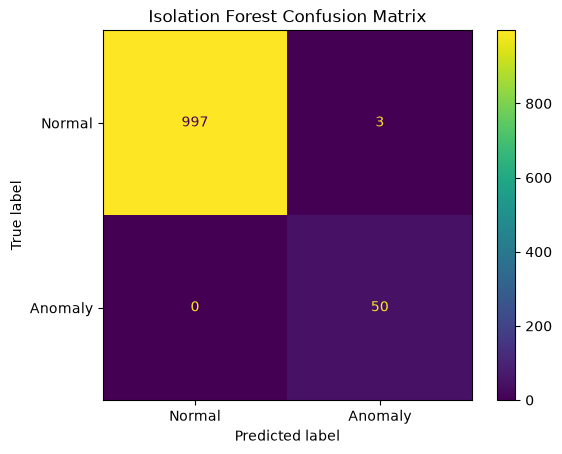

In [6]:
cm = confusion_matrix(y_true, y_pred_anomaly)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomaly"]
)

display.plot()

plt.title("Isolation Forest Confusion Matrix")
plt.show()

In [7]:
flagged_claims = claims[claims["anomaly_prediction"] == 1]

flagged_claims[
    [
        "claim_id",
        "patient_age",
        "length_of_stay",
        "num_procedures",
        "diagnosis_count",
        "claim_amount"
    ]
].head(10)

,claim_id,patient_age,length_of_stay,num_procedures,diagnosis_count,claim_amount
195,196,18,2,5,1,9666.394456
485,486,18,2,5,4,20496.886941
909,910,18,11,1,3,1482.599351
1000,1001,18,39,17,16,199362.099824
1001,1002,28,58,12,13,91100.052553
1002,1003,21,21,23,16,173641.743529
1003,1004,43,20,16,13,160844.208025
1004,1005,67,55,24,9,172099.859671
1005,1006,29,43,23,12,116903.575459
1006,1007,82,46,15,19,139046.538726


In [8]:
claims["rule_flag"] = (
    (claims["claim_amount"] > 50000) |
    (claims["length_of_stay"] > 15) |
    (claims["num_procedures"] > 8) |
    (claims["diagnosis_count"] > 7)
).astype(int)

print("Claims flagged by rules:", claims["rule_flag"].sum())

Claims flagged by rules: 50


In [9]:
print("Isolation Forest flagged:", claims["anomaly_prediction"].sum())

print("Rule-based flagged:", claims["rule_flag"].sum())

print(
    "Flagged by both:",
    ((claims["anomaly_prediction"] == 1) & (claims["rule_flag"] == 1)).sum()
)

Isolation Forest flagged: 53
Rule-based flagged: 50
Flagged by both: 50


In [10]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(anomaly_model, "../models/anomaly_detection_model.pkl")

joblib.dump(features, "../models/anomaly_features.pkl")

print("Anomaly detection model saved successfully!")

Anomaly detection model saved successfully!
